<a href="https://colab.research.google.com/github/Ashokyadhav/Econocausal/blob/Saiesh/Econocasual.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv("/content/Coupon_Impact.csv")

In [6]:
import pandas as pd
from google.colab import files

uploaded = files.upload()

file_name = next(iter(uploaded))

df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Saving Coupon_Impact.csv to Coupon_Impact (1).csv
Dataset loaded successfully!
Shape: (12959, 8)


,consumer_id,group,amount,purchase,redeem,pageviews,visit,discount
0,1,T1L,0.0,0,0,0,0,0.0
1,2,T1L,0.0,0,0,0,0,0.0
2,3,T1L,0.0,0,0,0,0,0.0
3,4,T1L,0.0,0,0,0,0,0.0
4,5,T1L,0.0,0,0,10,1,0.0


In [7]:

print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

print("\nExperimental Groups:")
print(df["group"].value_counts())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12959 entries, 0 to 12958
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   consumer_id  12959 non-null  int64  
 1   group        12959 non-null  object 
 2   amount       12959 non-null  float64
 3   purchase     12959 non-null  int64  
 4   redeem       12959 non-null  int64  
 5   pageviews    12959 non-null  int64  
 6   visit        12959 non-null  int64  
 7   discount     12959 non-null  float64
dtypes: float64(2), int64(5), object(1)
memory usage: 810.1+ KB

Missing Values:
consumer_id    0
group          0
amount         0
purchase       0
redeem         0
pageviews      0
visit          0
discount       0
dtype: int64

Duplicate Records:
0

Experimental Groups:
group
T1L    4787
T2H    3446
CGL    1998
T1H    1927
CGH     801
Name: count, dtype: int64


In [8]:

group_summary = df.groupby("group").agg(
    customers=("consumer_id", "count"),
    purchase_rate=("purchase", "mean"),
    visit_rate=("visit", "mean"),
    redemption_rate=("redeem", "mean")
)

# Average purchase amount among customers who purchased
purchase_amount = (
    df[df["purchase"] == 1]
    .groupby("group")["amount"]
    .mean()
)

group_summary["avg_purchase_amount"] = purchase_amount

print(group_summary.round(3))


       customers  purchase_rate  visit_rate  redemption_rate  \
group                                                          
CGH          801          0.042       0.227            0.000   
CGL         1998          0.010       0.106            0.000   
T1H         1927          0.066       0.446            0.008   
T1L         4787          0.026       0.346            0.005   
T2H         3446          0.093       0.442            0.021   

       avg_purchase_amount  
group                       
CGH                 34.956  
CGL                 25.890  
T1H                 37.693  
T1L                 27.821  
T2H                 31.899  


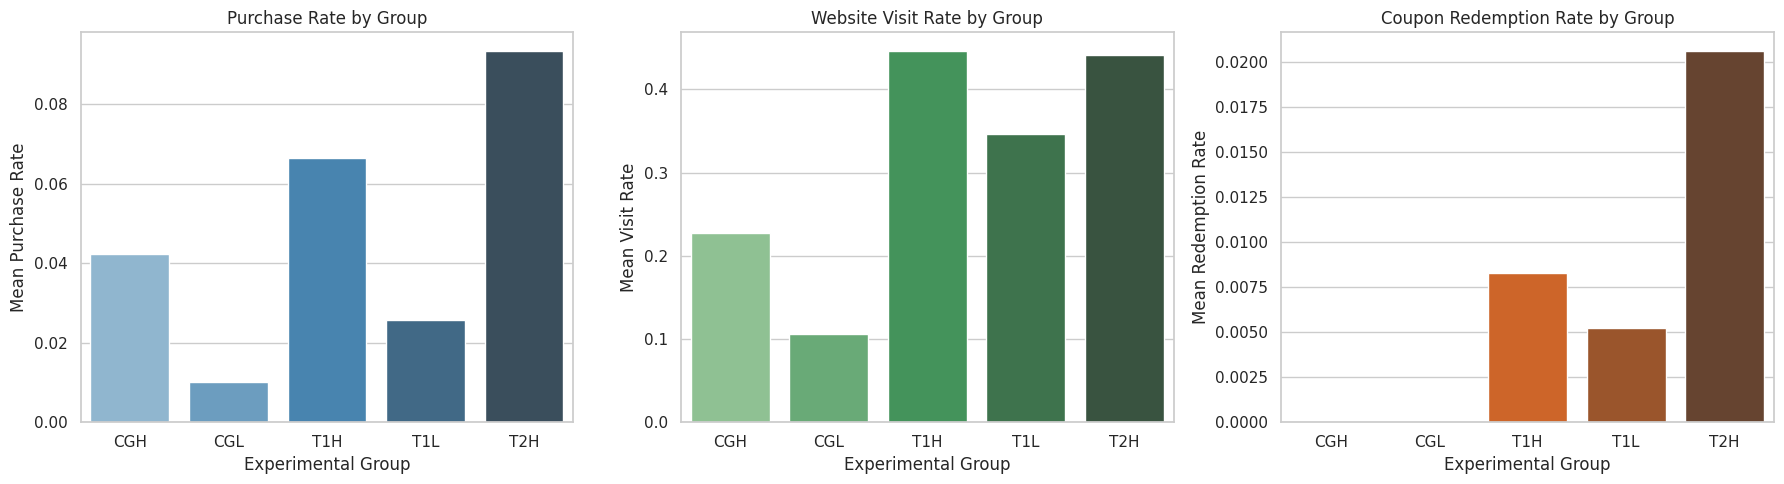

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set style
sns.set_theme(style="whitegrid")

# Prepare data for plotting by resetting index of group_summary
plot_data = group_summary.reset_index()

# Set up the plotting area
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Purchase Rate by Group
sns.barplot(x="group", y="purchase_rate", data=plot_data, ax=axes[0], palette="Blues_d", hue="group", legend=False)
axes[0].set_title("Purchase Rate by Group")
axes[0].set_xlabel("Experimental Group")
axes[0].set_ylabel("Mean Purchase Rate")

# 2. Visit Rate by Group
sns.barplot(x="group", y="visit_rate", data=plot_data, ax=axes[1], palette="Greens_d", hue="group", legend=False)
axes[1].set_title("Website Visit Rate by Group")
axes[1].set_xlabel("Experimental Group")
axes[1].set_ylabel("Mean Visit Rate")

# 3. Redemption Rate by Group
sns.barplot(x="group", y="redemption_rate", data=plot_data, ax=axes[2], palette="Oranges_d", hue="group", legend=False)
axes[2].set_title("Coupon Redemption Rate by Group")
axes[2].set_xlabel("Experimental Group")
axes[2].set_ylabel("Mean Redemption Rate")

plt.tight_layout()
plt.show()

Correlation Matrix:
           visit  pageviews  redeem  purchase  amount  discount
visit      1.000      0.928   0.129     0.313   0.307     0.306
pageviews  0.928      1.000   0.147     0.328   0.327     0.321
redeem     0.129      0.147   1.000     0.414   0.369     0.288
purchase   0.313      0.328   0.414     1.000   0.982     0.980
amount     0.307      0.327   0.369     0.982   1.000     0.965
discount   0.306      0.321   0.288     0.980   0.965     1.000


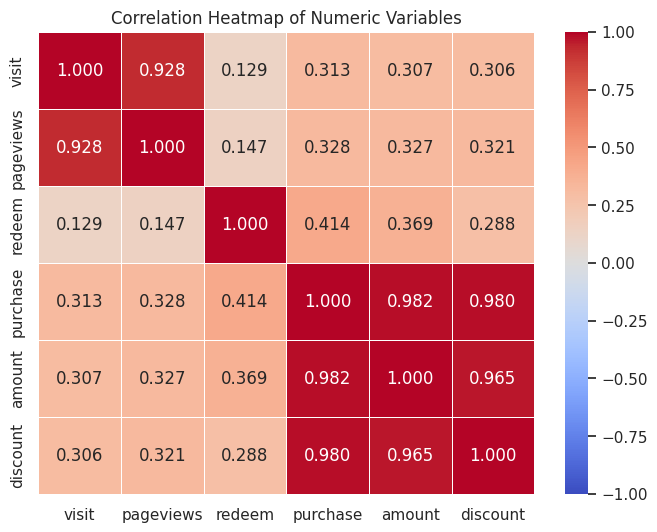

In [10]:
# Step 8: Correlation Analysis of Numeric Variables
import matplotlib.pyplot as plt
import seaborn as sns

# Select the columns relevant for correlation analysis
correlation_cols = ["visit", "pageviews", "redeem", "purchase", "amount", "discount"]
corr_matrix = df[correlation_cols].corr()

print("Correlation Matrix:")
print(corr_matrix.round(3))

# Plot the correlation heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".3f", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Correlation Heatmap of Numeric Variables")
plt.show()

In [11]:
# Step 10: Prepare and export a clean dataset for the causal inference module
clean_df = df.copy()

# Export to CSV
clean_output_path = "/content/Coupon_Impact_Clean.csv"
clean_df.to_csv(clean_output_path, index=False)

print(f"Clean dataset successfully prepared and saved to: {clean_output_path}")
print("Columns preserved:", list(clean_df.columns))
print("Final row count:", len(clean_df))

Clean dataset successfully prepared and saved to: /content/Coupon_Impact_Clean.csv
Columns preserved: ['consumer_id', 'group', 'amount', 'purchase', 'redeem', 'pageviews', 'visit', 'discount']
Final row count: 12959
